# RoT saliency vs training size and epochs (ToDo 16)

Fits RoT on growing, class-balanced training sets of digits (up to 5,260) and explains the **same test digits** every time, so you can watch the signed maps change: first as the training set grows, then as training runs longer at a fixed size. Shared weights (one weight per channel, the default) and unshared weights (one per pixel, `share_weights=False`) are fitted side by side. Choose the inputs (raw pixels or a pretrained backbone), the sizes, epochs and learning rate.

In [1]:
%pip install -q "ruleofthumb-rot[image,plot] @ git+https://github.com/staru09/Rule-of-Thumb.git@9705a0b" pandas scikit-learn

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## Settings

In [2]:
from pathlib import Path

OUT = Path("nb_out")             # results folder (created)

POOL = "optdigits"       # "digits": 1,437 training digits | "optdigits": + 3,823 UCI digits = 5,260
RESOLUTION = 8           # 8, or 32 (32 = UCI originals; only with POOL="digits" and raw input)
INPUTS = ["raw"]         # any of: "raw", "mobilenet_v3_small", "resnet18", "convnext_tiny", "efficientnet_b0"
MODES = ["shared", "unshared"]   # any of: "shared" (package default), "unshared"
SIZES = [50, 100, 200, 400, 800, 1437, 2000, 3000, 4000, 5260]   # training sizes (nested); largest = reference
EPOCHS = 2000            # epochs for the training-size sweep
EPOCH_SWEEP = [100, 300, 1000, 2000, 5000]   # epochs to compare at one size ([] to skip); longest = reference
EPOCH_SWEEP_SIZE = 1437  # training size for the epoch sweep
LEARNING_RATE = 0.05
WEIGHT_DECAY = 0.01
SEED = 0
DEVICE = "cuda"          # "auto" (cuda > mps > cpu), "cpu", "cuda"
THREADS = 8              # CPU threads
UCI_ZIP = Path("optdigits_uci.zip")   # UCI download, used for POOL="optdigits" and RESOLUTION=32

## Setup

In [3]:
import inspect
import json
import subprocess
import time
import urllib.request
import zipfile
import io

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

from ruleofthumb import fit_image
from ruleofthumb import plot as rot_plot

assert "share_weights" in inspect.signature(fit_image).parameters, "install the todo-16 branch of ruleofthumb"
OUT.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(THREADS)
if DEVICE == "auto":
    DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
if RESOLUTION == 32 and (POOL != "digits" or INPUTS != ["raw"]):
    raise ValueError("RESOLUTION=32 works only with POOL='digits' and INPUTS=['raw']")
print("device", DEVICE, "| torch", torch.__version__)

device cuda | torch 2.11.0+cu130


## Data

scikit-learn's 1,797 digits (8×8, scaled 0–1) in the repo's artifact order, and a black box: the repo's
TinyCNN trained on this data, its predictions are the labels RoT explains. Test = the PR's stratified 20% (360 digits, seed 0).

In [4]:
from sklearn.datasets import load_digits


class TinyCNN(torch.nn.Module):  # = tests/integration/cnn.py
    def __init__(self, n_classes=10, in_channels=1):
        super().__init__()
        self.net = torch.nn.Sequential(
            torch.nn.Conv2d(in_channels, 8, kernel_size=3, padding=1), torch.nn.ReLU(),
            torch.nn.Conv2d(8, 8, kernel_size=3, padding=1), torch.nn.ReLU(),
            torch.nn.Flatten(), torch.nn.Linear(8 * 8 * 8, n_classes),
        )

    def forward(self, x):
        return self.net(x)


def train_tiny_cnn(x, y, epochs=40, batch=64):  # = generate_artifacts._train_tiny_cnn (CPU)
    torch.manual_seed(0)
    cnn = TinyCNN(n_classes=10)
    optimiser, loss_fn = torch.optim.AdamW(cnn.parameters(), lr=1e-3), torch.nn.CrossEntropyLoss()
    xt, yt = torch.from_numpy(x), torch.from_numpy(y)
    for _ in range(epochs):
        cnn.train()
        perm = torch.randperm(len(xt))
        for i in range(0, len(xt), batch):
            sel = perm[i:i + batch]
            optimiser.zero_grad()
            loss_fn(cnn(xt[sel]), yt[sel]).backward()
            optimiser.step()
    return cnn.eval()


def uci(member):
    """One file from the UCI optdigits zip (downloaded once)."""
    if not UCI_ZIP.exists():
        url = "https://archive.ics.uci.edu/static/public/80/optical+recognition+of+handwritten+digits.zip"
        print("downloading", url)
        UCI_ZIP.write_bytes(urllib.request.urlopen(urllib.request.Request(url, headers={"User-Agent": "curl/8"}), timeout=120).read())
    return zipfile.ZipFile(UCI_ZIP).read(member)

digits = load_digits()
rng = np.random.RandomState(0)
keep = np.concatenate([rng.choice(np.flatnonzero(digits.target == c), size=(digits.target == c).sum(), replace=False)
                       for c in range(10)])
rng.shuffle(keep)
gray8 = (digits.data[keep] / 16.0).astype(np.float32).reshape(-1, 1, 8, 8)
true_y = digits.target[keep].astype(np.int64)

cnn = train_tiny_cnn(gray8, true_y)
with torch.no_grad():
    y_all = cnn(torch.from_numpy(gray8)).argmax(1).numpy().astype(np.int64)
print(f"black box trained: agrees with the true digit on {(y_all == true_y).mean():.4f} of the 1,797")

def split(y, seed=0):
    rng = np.random.RandomState(seed)
    train, test = [], []
    for c in np.unique(y):
        idx = np.flatnonzero(y == c)
        rng.shuffle(idx)
        cut = round(0.8 * len(idx))
        train.append(idx[:cut])
        test.append(idx[cut:])
    return np.sort(np.concatenate(train)), np.sort(np.concatenate(test))

def round_robin(idx, y, seed):
    """Order idx so every prefix is class-balanced (classes take turns, shuffled within class)."""
    rng = np.random.RandomState(seed)
    per_class = []
    for c in range(10):
        members = idx[y[idx] == c].copy()
        rng.shuffle(members)
        per_class.append(list(members))
    order = []
    while any(per_class):
        for members in per_class:
            if members:
                order.append(members.pop(0))
    return np.array(order)

def optdigits_tra():
    raw = np.loadtxt(io.BytesIO(uci("optdigits.tra")), delimiter=",", dtype=np.float32)
    return (raw[:, :64] / 16.0).reshape(-1, 1, 8, 8)

def originals32():
    """UCI's 32x32 bitmaps of the same 1,797 digits (optdigits-orig.windep, sklearn's order)."""
    # .Z = unix compress; gzip -d reads it (Linux / macOS / Kaggle)
    text = subprocess.run(["gzip", "-dc"], input=uci("optdigits-orig.windep.Z"), capture_output=True, check=True).stdout
    lines = text.decode().splitlines()[21:]
    big = np.array([[[int(ch) for ch in row] for row in lines[s:s + 32]] for s in range(0, len(lines) - 32, 33)],
                   dtype=np.float32)
    assert np.array_equal(big.reshape(-1, 8, 4, 8, 4).sum((2, 4)), digits.images), "32x32 originals do not match"
    return big[keep][:, None]


train_idx, test_idx = split(y_all)
pool_gray = gray8[round_robin(train_idx, y_all, 0)]
pool_y = y_all[round_robin(train_idx, y_all, 0)]
if POOL == "optdigits":
    extra = optdigits_tra()
    with torch.no_grad():
        extra_y = cnn(torch.from_numpy(extra)).argmax(1).numpy().astype(np.int64)
    order = round_robin(np.arange(len(extra)), extra_y, 1)
    pool_gray, pool_y = np.concatenate([pool_gray, extra[order]]), np.concatenate([pool_y, extra_y[order]])
test_gray, test_y = gray8[test_idx], y_all[test_idx]

if RESOLUTION == 32:  # UCI 32x32 originals of the same 1,797 digits, same order
    gray32 = originals32()
    pool_gray = gray32[round_robin(train_idx, y_all, 0)]
    test_gray = gray32[test_idx]

SIZES = [n for n in SIZES if n <= len(pool_y)]
EPOCH_SWEEP_SIZE = min(EPOCH_SWEEP_SIZE, len(pool_y))
print(f"pool {len(pool_y)} training digits, test {len(test_y)}, sizes {SIZES}")
print("pool class counts", np.bincount(pool_y).tolist())

black box trained: agrees with the true digit on 0.9972 of the 1,797
downloading https://archive.ics.uci.edu/static/public/80/optical+recognition+of+handwritten+digits.zip
pool 5260 training digits, test 360, sizes [50, 100, 200, 400, 800, 1437, 2000, 3000, 4000, 5260]
pool class counts [525, 534, 526, 552, 515, 493, 536, 546, 502, 531]


## Inputs

`raw` = the pixels themselves. A backbone name = that ImageNet model's last feature maps
(e.g. MobileNet 576×7×7), computed once from the 8×8 digit upscaled to RGB and cached in `OUT`.

In [5]:
from torchvision import models as tv

BACKBONES = {
    "mobilenet_v3_small": (tv.mobilenet_v3_small, tv.MobileNet_V3_Small_Weights.IMAGENET1K_V1, lambda m, b: m.features(b)),
    "resnet18": (tv.resnet18, tv.ResNet18_Weights.IMAGENET1K_V1, lambda m, b: torch.nn.Sequential(*list(m.children())[:-2])(b)),
    "convnext_tiny": (tv.convnext_tiny, tv.ConvNeXt_Tiny_Weights.IMAGENET1K_V1, lambda m, b: m.features(b)),
    "efficientnet_b0": (tv.efficientnet_b0, tv.EfficientNet_B0_Weights.IMAGENET1K_V1, lambda m, b: m.features(b)),
}


def backbone_features(gray, name):
    builder, weights, extract = BACKBONES[name]
    model, transform, out = builder(weights=weights).eval().to(DEVICE), weights.transforms(), []
    with torch.no_grad():
        for start in range(0, len(gray), 256):
            chunk = gray[start:start + 256]
            batch = torch.stack([transform(Image.fromarray((g[0] * 255).clip(0, 255).astype(np.uint8), mode="L").convert("RGB"))
                                 for g in chunk]).to(DEVICE)
            out.append(extract(model, batch).cpu().numpy().astype(np.float32))
    return np.concatenate(out)


def inputs(name):
    if name == "raw":
        return pool_gray, test_gray
    cache = OUT / f"features_{name}_{POOL}.npz"
    if not cache.exists():
        t = time.time()
        np.savez(cache, pool=backbone_features(pool_gray, name), test=backbone_features(test_gray, name))
        print(f"{name}: features in {time.time() - t:.0f}s")
    f = np.load(cache)
    return f["pool"], f["test"]

## Sample digits

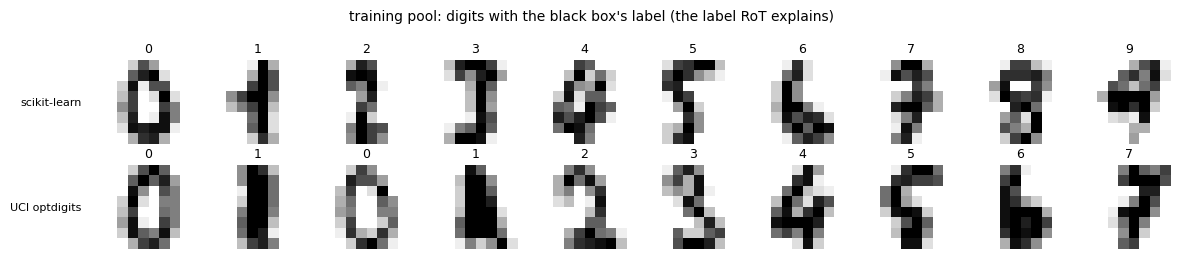

In [6]:
n_first = len(train_idx)   # pool digits before this index are scikit-learn's; after it, UCI optdigits
show = list(range(12)) + (list(range(n_first, n_first + 12)) if len(pool_y) > n_first else list(range(12, 24)))
fig, axes = plt.subplots(2, 10, figsize=(12, 2.6))
for ax, i in zip(axes.ravel(), show):
    ax.imshow(pool_gray[i, 0], cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(f"{pool_y[i]}", fontsize=9)
    ax.axis("off")
axes[0, 0].text(-0.3, 0.5, "scikit-learn", transform=axes[0, 0].transAxes, ha="right", va="center", fontsize=8)
axes[1, 0].text(-0.3, 0.5, "UCI optdigits" if len(pool_y) > n_first else "scikit-learn",
                transform=axes[1, 0].transAxes, ha="right", va="center", fontsize=8)
fig.suptitle("training pool: digits with the black box's label (the label RoT explains)", fontsize=10)
fig.tight_layout()
fig.savefig(OUT / "sample_digits.png", dpi=90)
plt.show()

## Fitting

In [15]:
def to_np(v):
    return v.detach().cpu().numpy() if torch.is_tensor(v) else np.asarray(v)


fits = {}


def fit_one(name, mode, n, epochs):
    key = (name, mode, n, epochs)
    if key not in fits:
        x_pool, x_test = inputs(name)
        t = time.time()
        exp = fit_image(pool_y[:n], x_pool[:n], n_classes=10, share_weights=mode == "shared", epochs=epochs,
                        batch_size=n, learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY, seed=SEED, device=DEVICE)
        secs = time.time() - t
        test_pred = to_np(exp.predict(torch.from_numpy(x_test)))
        train_pred = to_np(exp.predict(torch.from_numpy(x_pool[:n])))
        imp = to_np(exp.get_explanation(x_test))
        fits[key] = {
            "row": {"input": name, "mode": mode, "n_train": n, "epochs": epochs,
                    "train_agreement": float((train_pred == pool_y[:n]).mean()),
                    "test_agreement": float((test_pred == test_y).mean()), "fit_secs": round(secs, 1)},
            "map": imp[np.arange(len(test_y)), test_y],
            "template": to_np(exp.model.a)[:, 0] if name == "raw" and mode == "unshared" else None,
        }
        print(fits[key]["row"])
    return fits[key]


mean_corr = lambda a, b: float(np.nanmean([np.corrcoef(p.ravel(), q.ravel())[0, 1] for p, q in zip(a, b)]))
ink = test_gray[:, 0] > 0


def sweep(axis_values, key_of):
    rows = []
    for name in INPUTS:
        for mode in MODES:
            last = fit_one(*key_of(name, mode, axis_values[-1]))["map"]
            prev = None
            for v in axis_values:
                f = fit_one(*key_of(name, mode, v))
                m = f["map"]
                row = dict(f["row"], map_vs_last=mean_corr(m, last),
                           map_vs_previous=mean_corr(m, prev) if prev is not None else np.nan,
                           blank_share=float((np.abs(m) * ~ink).sum() / np.abs(m).sum()) if m.shape[-1] == ink.shape[-1] else np.nan)
                rows.append(row)
                prev = m
    return pd.DataFrame(rows)


def upscale(a, size=128):
    t = torch.from_numpy(np.asarray(a, dtype=np.float32))[None, None]
    return torch.nn.functional.interpolate(t, size=(size, size), mode="bilinear", align_corners=False)[0, 0].numpy()


ROWS = [int(np.flatnonzero(test_y == c)[0]) for c in range(10)]


def charts(table, x, xlabel, fname, title):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
    many_inputs = table["input"].nunique() > 1
    for (name, mode), g in table.groupby(["input", "mode"], sort=False):
        input_prefix = f"{name} " if many_inputs else ""
        who_test = f"{input_prefix}{mode} (test)"
        who_train = f"{input_prefix}{mode} (train)"
        who_general = f"{input_prefix}{mode}"

        line, = axes[0].plot(g[x], g["test_agreement"], marker="o", label=who_test)
        axes[0].plot(g[x], g["train_agreement"], marker=".", ls="--", color=line.get_color(), label=who_train)
        axes[1].plot(g[x], g["map_vs_last"], marker="o", color=line.get_color(), label=who_general)
        axes[2].plot(g[x], g["blank_share"], marker="o", color=line.get_color(), label=who_general)

    panels = [
        ("1. Black-Box Agreement", "Agreement (higher = better)"),
        ("2. Saliency Map Similarity", "Similarity to final map"),
        ("3. Off-Ink Background Share", "Noise ratio (lower = cleaner)")
    ]
    for ax, (question, ylabel) in zip(axes, panels):
        ax.set_xscale("log")
        values = sorted(table[x].unique())
        ax.set_xticks(values, [f"{v:,}" for v in values], rotation=45, fontsize=8)
        ax.minorticks_off()
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel, fontsize=9)
        ax.set_title(question, fontsize=10)
        ax.grid(alpha=0.3)
        ax.legend(frameon=False, fontsize=7)
    axes[0].set_ylim(0, 1.02)
    axes[1].set_ylim(-0.05, 1.02)
    axes[2].set_ylim(bottom=0)
    fig.suptitle(title, fontsize=11)
    fig.tight_layout()
    fig.savefig(OUT / fname, dpi=110)
    plt.show()


def map_grid(maps_by_col, col_labels, title, fname):
    fig, axes = plt.subplots(len(ROWS), len(maps_by_col) + 1, figsize=(1.6 * (len(maps_by_col) + 1), 1.65 * len(ROWS)))
    for r, i in enumerate(ROWS):
        axes[r, 0].imshow(test_gray[i, 0], cmap="gray", vmin=0, vmax=1)
        axes[r, 0].axis("off")
        for j, m in enumerate(maps_by_col):
            rot_plot.saliency(upscale(m[i]), ax=axes[r, j + 1])
            if r == 0:
                axes[r, j + 1].set_title(col_labels[j], fontsize=9)
    fig.suptitle(title + ": red = toward the black-box class, blue = against", fontsize=10)
    fig.tight_layout()
    fig.savefig(OUT / fname, dpi=90)
    plt.show()


def template_grid(templates, row_labels, title, fname):
    fig, axes = plt.subplots(len(templates), 10, figsize=(14, 1.45 * len(templates)))
    axes = np.atleast_2d(axes)
    for r, t in enumerate(templates):
        for k in range(10):
            rot_plot.saliency(upscale(t[k]), ax=axes[r, k])
            if r == 0:
                axes[r, k].set_title(f"class {k}", fontsize=9)
        axes[r, 0].text(-0.15, 0.5, row_labels[r], transform=axes[r, 0].transAxes, ha="right", va="center", fontsize=8)
    fig.suptitle(title + ": red = ink here raises class k, blue = lowers it", fontsize=10)
    fig.tight_layout()
    fig.savefig(OUT / fname, dpi=90)
    plt.show()

## Part 1: does more training data give better maps?

We teach RoT to copy the black box with 50 digits, then 100, 200, ... up to the largest size, always with
`EPOCHS` epochs, and draw maps for the same 360 test digits each time. Each run is checked with three questions
(the three charts below; the table has the same numbers):

1. **Does RoT give the black box's answer?** (`test_agreement`, `train_agreement`) Out of the digits, the share
   where RoT and the black box give the same answer. Solid line = digits RoT never saw (the honest score);
   dashed = the digits it learned from. 1 = always the same answer, 0.1 = guessing.
2. **Do the maps stop changing?** (`map_vs_last`) For each test digit, how alike its map is to its map from the
   biggest run (1 = the same picture). If the line climbs to 1, adding data stops changing the maps.
   `map_vs_previous` in the table is the same against the run just before.
3. **How much colour lands on empty background?** (`blank_share`) The explanation should sit on the digit's
   ink; colour on empty pixels is mostly noise. Lower = cleaner.

In [8]:
size_table = sweep(SIZES, lambda name, mode, n: (name, mode, n, EPOCHS))
size_table.to_csv(OUT / "metrics_sizes.csv", index=False)
json.dump({"POOL": POOL, "RESOLUTION": RESOLUTION, "INPUTS": INPUTS, "MODES": MODES, "SIZES": SIZES, "EPOCHS": EPOCHS,
           "EPOCH_SWEEP": EPOCH_SWEEP, "EPOCH_SWEEP_SIZE": EPOCH_SWEEP_SIZE, "LEARNING_RATE": LEARNING_RATE,
           "WEIGHT_DECAY": WEIGHT_DECAY, "SEED": SEED, "DEVICE": DEVICE}, open(OUT / "settings.json", "w"), indent=1)
size_table.round(3)

/usr/local/lib/python3.13/dist-packages/ruleofthumb/explain.py:84: UserWarning: low train agreement (0.123 < 0.75); explanations may be unreliable. Check surrogate-vs-blackbox agreement before trusting them (see the capacity docs).
  warnings.warn(


{'input': 'raw', 'mode': 'shared', 'n_train': 5260, 'epochs': 2000, 'train_agreement': 0.12262357414448669, 'test_agreement': 0.1, 'fit_secs': 4.8}


/usr/local/lib/python3.13/dist-packages/ruleofthumb/explain.py:84: UserWarning: low train agreement (0.140 < 0.75); explanations may be unreliable. Check surrogate-vs-blackbox agreement before trusting them (see the capacity docs).
  warnings.warn(


{'input': 'raw', 'mode': 'shared', 'n_train': 50, 'epochs': 2000, 'train_agreement': 0.14, 'test_agreement': 0.1, 'fit_secs': 3.6}


/usr/local/lib/python3.13/dist-packages/ruleofthumb/explain.py:84: UserWarning: low train agreement (0.130 < 0.75); explanations may be unreliable. Check surrogate-vs-blackbox agreement before trusting them (see the capacity docs).
  warnings.warn(


{'input': 'raw', 'mode': 'shared', 'n_train': 100, 'epochs': 2000, 'train_agreement': 0.13, 'test_agreement': 0.11944444444444445, 'fit_secs': 3.6}


... (11 outputs left out)

{'input': 'raw', 'mode': 'shared', 'n_train': 3000, 'epochs': 2000, 'train_agreement': 0.12033333333333333, 'test_agreement': 0.10833333333333334, 'fit_secs': 4.0}


/usr/local/lib/python3.13/dist-packages/ruleofthumb/explain.py:84: UserWarning: low train agreement (0.118 < 0.75); explanations may be unreliable. Check surrogate-vs-blackbox agreement before trusting them (see the capacity docs).
  warnings.warn(


{'input': 'raw', 'mode': 'shared', 'n_train': 4000, 'epochs': 2000, 'train_agreement': 0.1185, 'test_agreement': 0.1361111111111111, 'fit_secs': 5.9}
{'input': 'raw', 'mode': 'unshared', 'n_train': 5260, 'epochs': 2000, 'train_agreement': 0.9661596958174905, 'test_agreement': 0.975, 'fit_secs': 4.0}
{'input': 'raw', 'mode': 'unshared', 'n_train': 50, 'epochs': 2000, 'train_agreement': 1.0, 'test_agreement': 0.9111111111111111, 'fit_secs': 3.5}
{'input': 'raw', 'mode': 'unshared', 'n_train': 100, 'epochs': 2000, 'train_agreement': 1.0, 'test_agreement': 0.8972222222222223, 'fit_secs': 3.7}
{'input': 'raw', 'mode': 'unshared', 'n_train': 200, 'epochs': 2000, 'train_agreement': 0.995, 'test_agreement': 0.9527777777777777, 'fit_secs': 3.8}
{'input': 'raw', 'mode': 'unshared', 'n_train': 400, 'epochs': 2000, 'train_agreement': 0.985, 'test_agreement': 0.9527777777777777, 'fit_secs': 3.7}
{'input': 'raw', 'mode': 'unshared', 'n_train': 800, 'epochs': 2000, 'train_agreement': 0.98, 'test_agre

,input,mode,n_train,epochs,train_agreement,test_agreement,fit_secs,map_vs_last,map_vs_previous,blank_share
0,raw,shared,50,2000,0.140,0.100,3.6,-0.606,NaN,0.437
1,raw,shared,100,2000,0.130,0.119,3.6,-0.006,0.400,0.431
2,raw,shared,200,2000,0.150,0.128,3.6,0.794,0.200,0.448
3,raw,shared,400,2000,0.118,0.117,3.8,0.006,-0.200,0.411
4,raw,shared,800,2000,0.116,0.125,3.8,0.200,0.394,0.422
5,raw,shared,1437,2000,0.115,0.117,3.8,0.794,0.406,0.427
6,raw,shared,2000,2000,0.122,0.111,3.9,0.600,0.394,0.433
7,raw,shared,3000,2000,0.120,0.108,4.0,0.806,0.406,0.427
8,raw,shared,4000,2000,0.118,0.136,5.9,0.406,0.600,0.433
9,raw,shared,5260,2000,0.123,0.100,4.8,1.000,0.406,0.432


### Charts

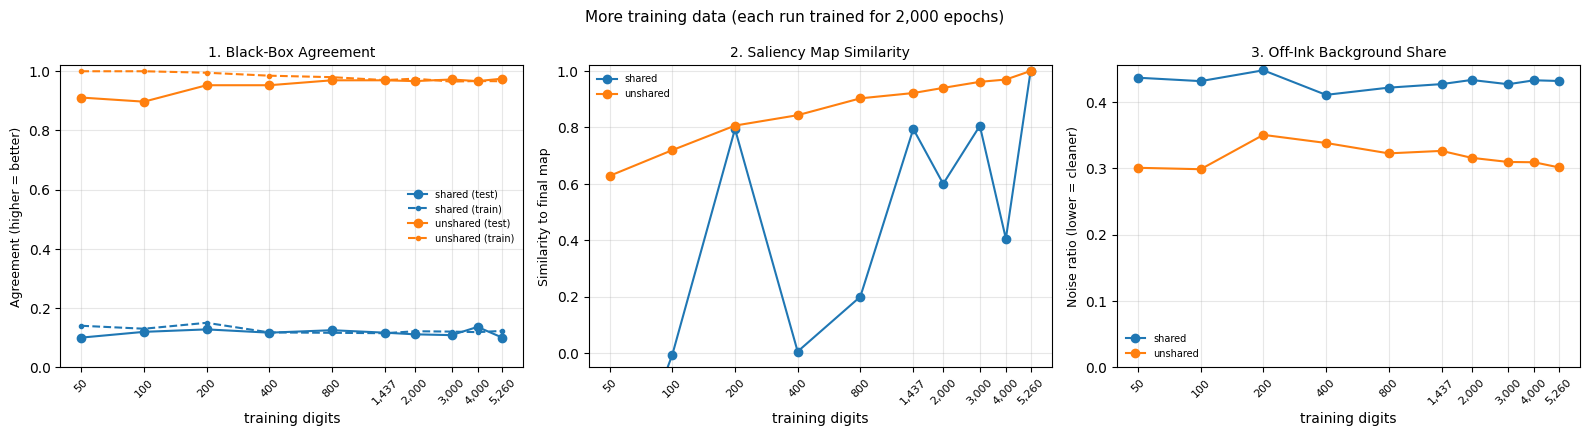

In [16]:
charts(size_table, "n_train", "training digits", "chart_sizes.png",
       f"More training data (each run trained for {EPOCHS:,} epochs)")

### Saliency Map Evolution by Training Size (Rows: Test Digits, Columns: Training Size)

This grid visualizes the signed saliency maps across different training dataset sizes ($n$) for one test digit of each class (0–9). The raw explanation maps are upscaled to $128 \times 128$ pixels and rendered using `plot.saliency` to highlight key pixels.

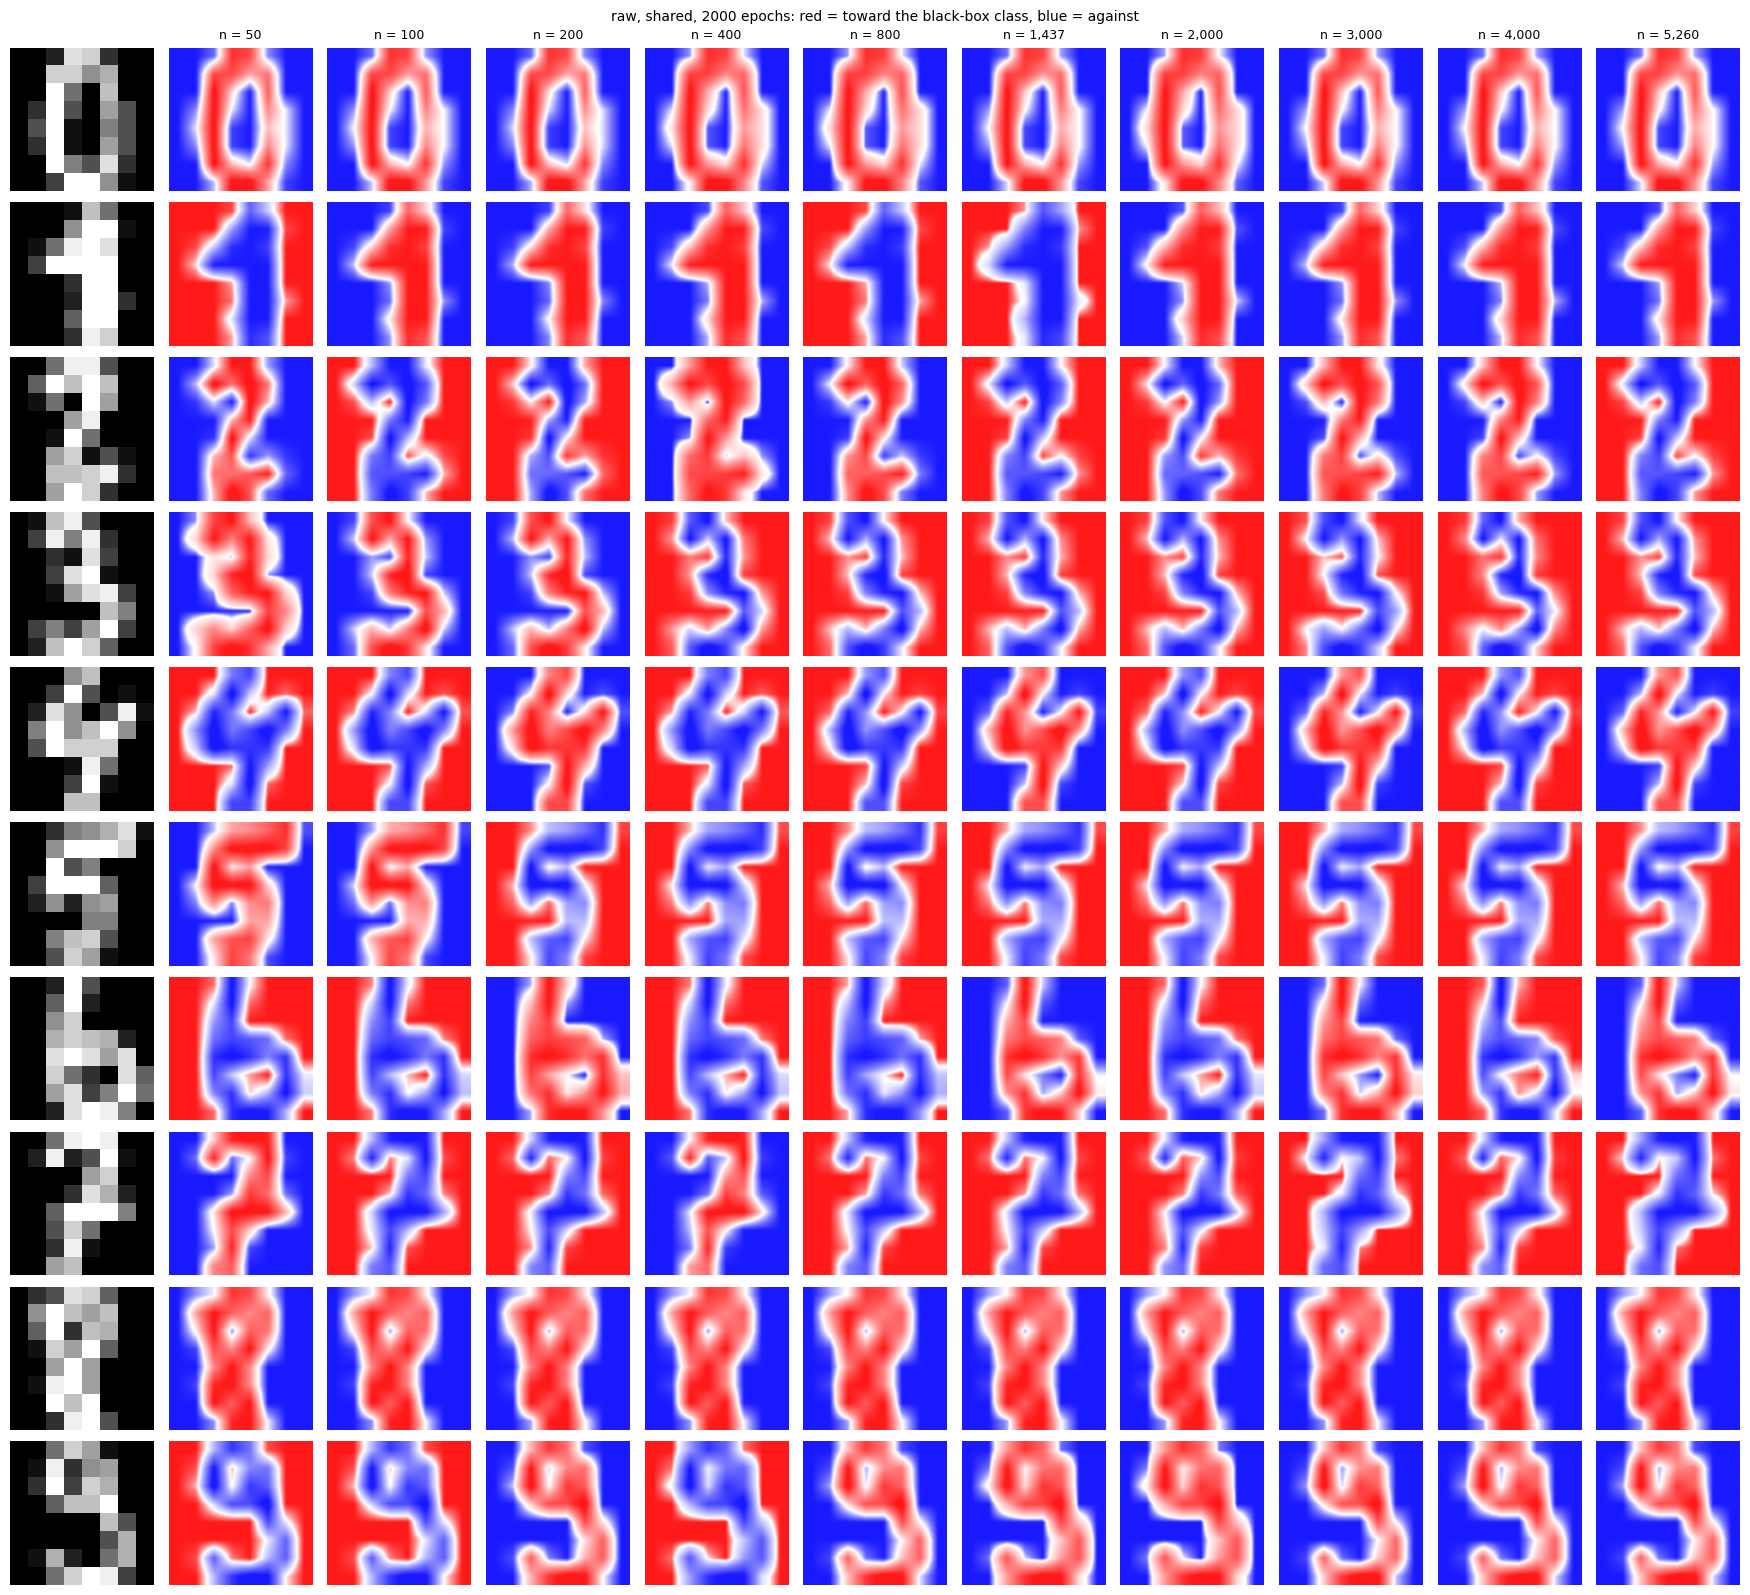

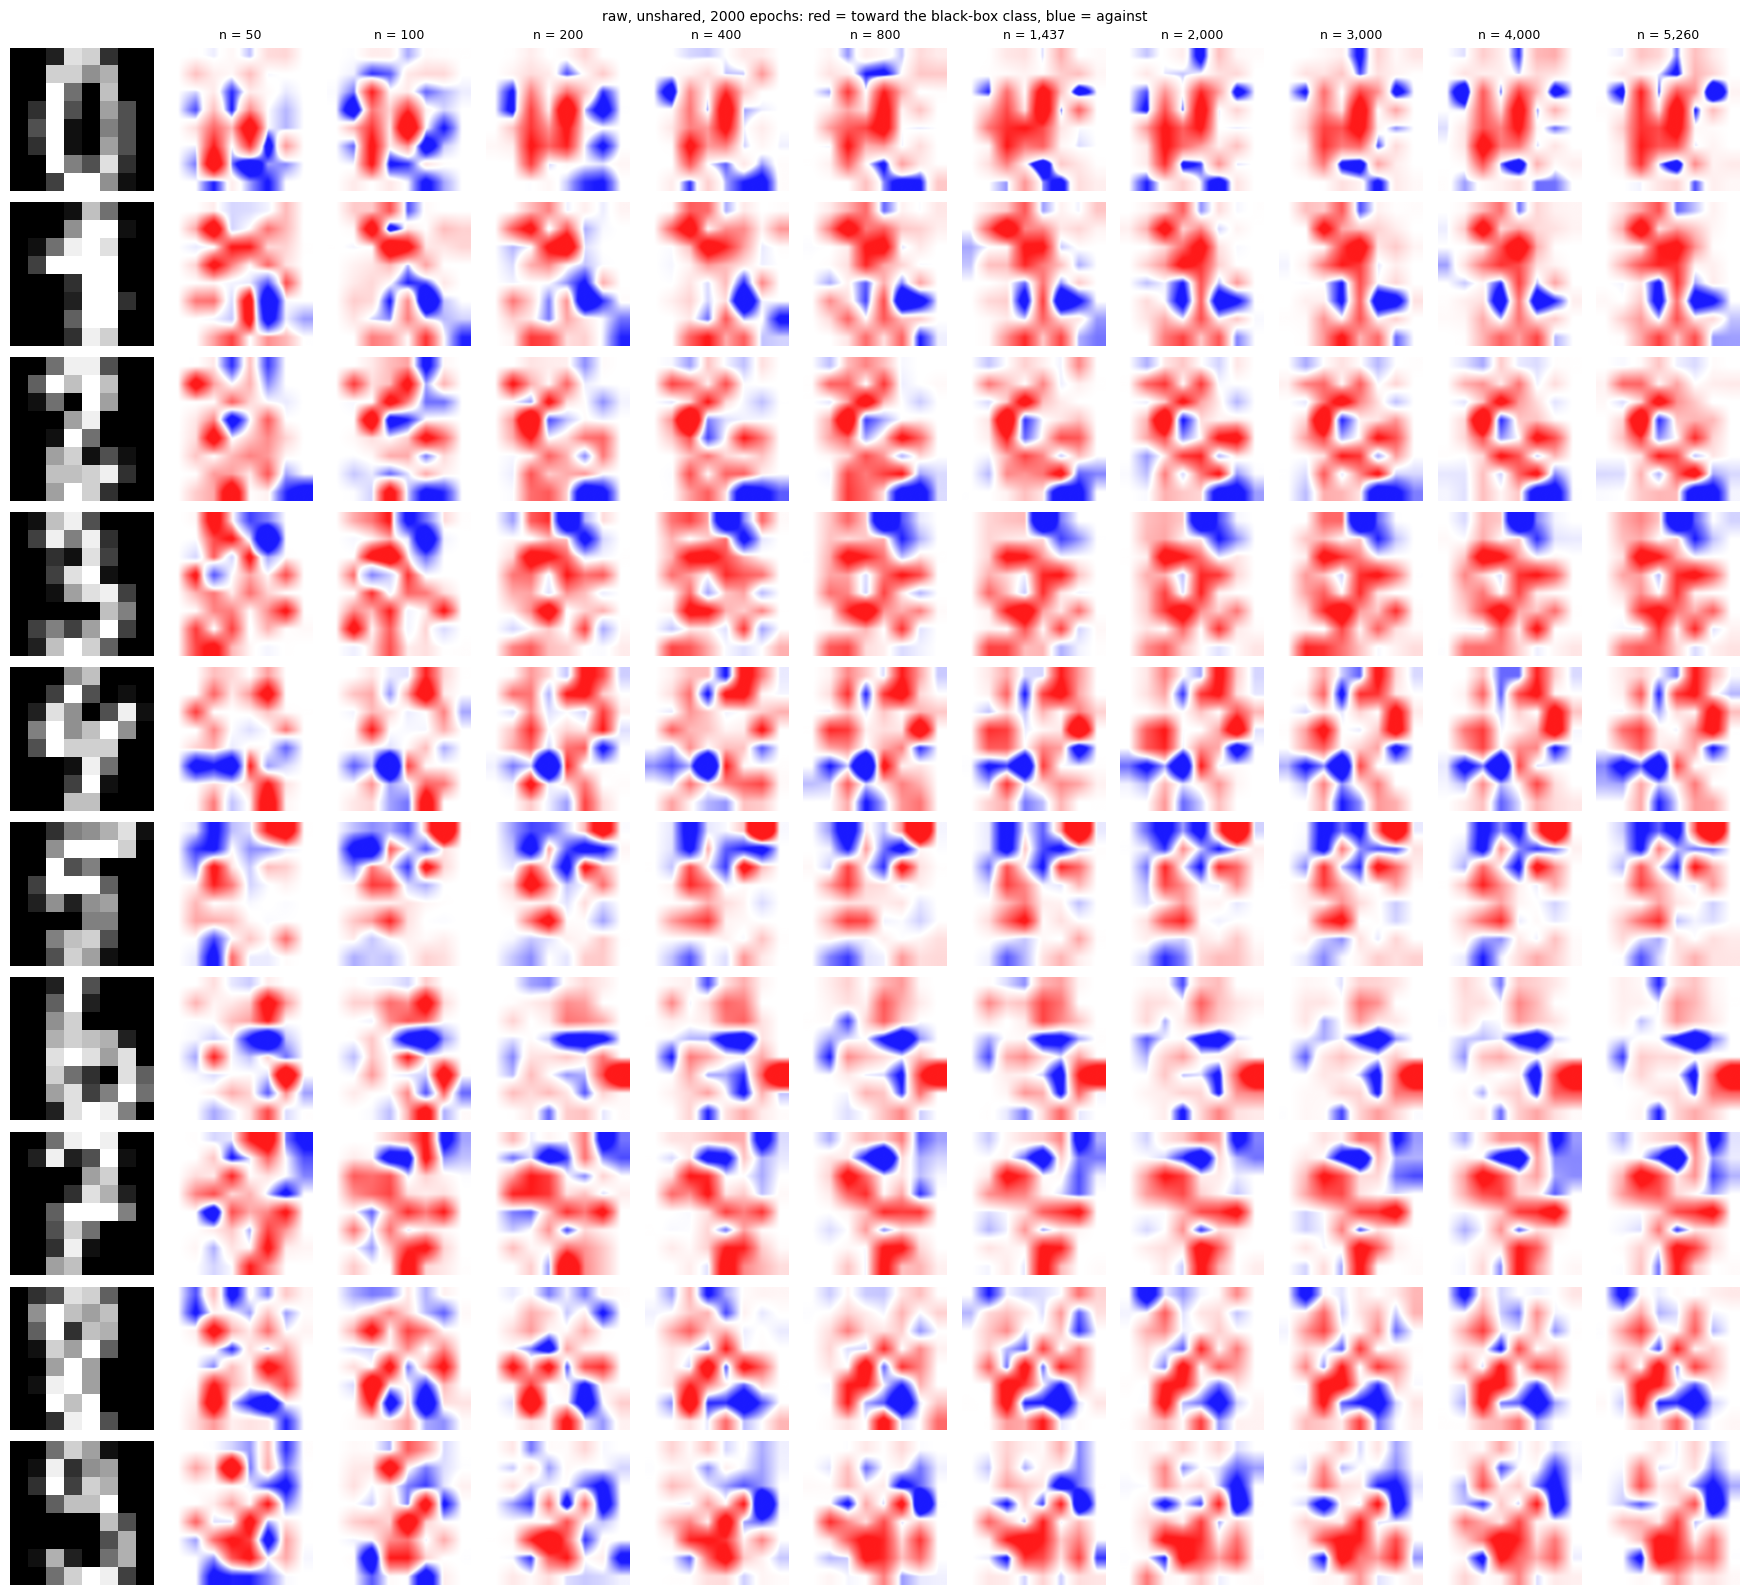

In [10]:
for name in INPUTS:
    for mode in MODES:
        map_grid([fits[(name, mode, n, EPOCHS)]["map"] for n in SIZES], [f"n = {n:,}" for n in SIZES],
                 f"{name}, {mode}, {EPOCHS} epochs", f"maps_sizes_{name}_{mode}.png")

### Side-by-Side Saliency Comparison (Digit vs. Shared vs. Unshared Weights) at Maximum Dataset Size

We compare the original test digits directly against their corresponding Rule of Thumb (RoT) explanations under both fitting strategies using the largest available dataset size ($n = 5,260$).

* **Top Row:** Original $8 \times 8$ grayscale test digits with their black box predicted labels.
* **Middle Row (shared):** Saliency maps fitted using a single shared weight parameter per channel (the package default).
* **Bottom Row (unshared):** Saliency maps fitted using unshared weights, allowing one independent parameter per pixel.

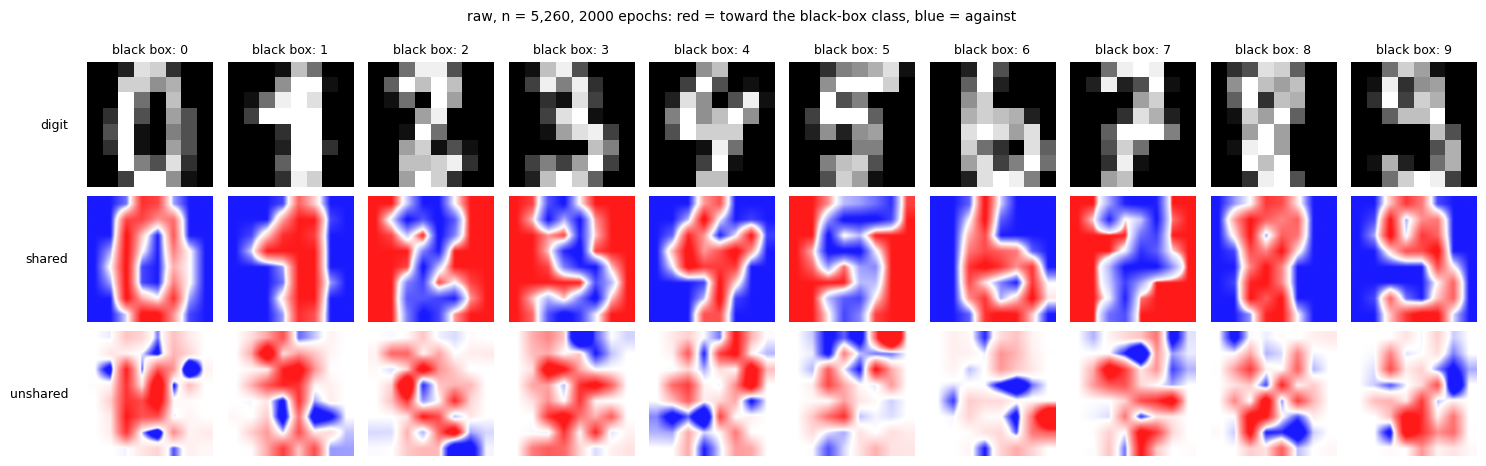

In [11]:
if {"shared", "unshared"} <= set(MODES):
    for name in INPUTS:
        fig, axes = plt.subplots(3, 10, figsize=(15, 4.9))
        for k, i in enumerate(ROWS):
            axes[0, k].imshow(test_gray[i, 0], cmap="gray", vmin=0, vmax=1)
            axes[0, k].set_title(f"black box: {test_y[i]}", fontsize=9)
            axes[0, k].axis("off")
            for r, mode in enumerate(["shared", "unshared"], start=1):
                rot_plot.saliency(upscale(fits[(name, mode, SIZES[-1], EPOCHS)]["map"][i]), ax=axes[r, k])
        for r, label in enumerate(["digit", "shared", "unshared"]):
            axes[r, 0].text(-0.15, 0.5, label, transform=axes[r, 0].transAxes, ha="right", va="center", fontsize=9)
        fig.suptitle(f"{name}, n = {SIZES[-1]:,}, {EPOCHS} epochs: red = toward the black-box class, blue = against",
                     fontsize=10)
        fig.tight_layout()
        fig.savefig(OUT / f"shared_vs_unshared_{name}.png", dpi=90)
        plt.show()
else:
    print("select both modes to compare shared and unshared")

## Part 2: Does training for longer epochs improve saliency maps?

To understand the effect of optimization duration, we keep the training set size fixed at `EPOCH_SWEEP_SIZE` digits and vary the total number of training epochs (`EPOCH_SWEEP`). We evaluate the resulting models on the same three questions:

1. **Does RoT give the black box's answer?** We track the agreement with the black box model on both training and validation sets as training progresses.
2. **Do the maps stop changing?** We measure how similar each test digit's map is to the final map generated at the maximum number of epochs (where 1 indicates identical maps).
3. **How much colour lands on empty background?** We quantify the fraction of the explanation map's magnitude that falls outside the active pixels (the digit's ink), where lower values represent cleaner explanations.

In [12]:
if EPOCH_SWEEP:
    epoch_table = sweep(EPOCH_SWEEP, lambda name, mode, e: (name, mode, EPOCH_SWEEP_SIZE, e))
    epoch_table.to_csv(OUT / "metrics_epochs.csv", index=False)
    display(epoch_table.round(3))
else:
    print("EPOCH_SWEEP is empty: skipped")

/usr/local/lib/python3.13/dist-packages/ruleofthumb/explain.py:84: UserWarning: low train agreement (0.120 < 0.75); explanations may be unreliable. Check surrogate-vs-blackbox agreement before trusting them (see the capacity docs).
  warnings.warn(


{'input': 'raw', 'mode': 'shared', 'n_train': 1437, 'epochs': 5000, 'train_agreement': 0.12038970076548365, 'test_agreement': 0.11666666666666667, 'fit_secs': 8.9}


/usr/local/lib/python3.13/dist-packages/ruleofthumb/explain.py:84: UserWarning: low train agreement (0.116 < 0.75); explanations may be unreliable. Check surrogate-vs-blackbox agreement before trusting them (see the capacity docs).
  warnings.warn(


{'input': 'raw', 'mode': 'shared', 'n_train': 1437, 'epochs': 100, 'train_agreement': 0.11551844119693806, 'test_agreement': 0.11388888888888889, 'fit_secs': 0.2}


/usr/local/lib/python3.13/dist-packages/ruleofthumb/explain.py:84: UserWarning: low train agreement (0.129 < 0.75); explanations may be unreliable. Check surrogate-vs-blackbox agreement before trusting them (see the capacity docs).
  warnings.warn(


{'input': 'raw', 'mode': 'shared', 'n_train': 1437, 'epochs': 300, 'train_agreement': 0.12943632567849686, 'test_agreement': 0.125, 'fit_secs': 0.6}


/usr/local/lib/python3.13/dist-packages/ruleofthumb/explain.py:84: UserWarning: low train agreement (0.110 < 0.75); explanations may be unreliable. Check surrogate-vs-blackbox agreement before trusting them (see the capacity docs).
  warnings.warn(


{'input': 'raw', 'mode': 'shared', 'n_train': 1437, 'epochs': 1000, 'train_agreement': 0.10995128740431455, 'test_agreement': 0.1111111111111111, 'fit_secs': 1.9}
{'input': 'raw', 'mode': 'unshared', 'n_train': 1437, 'epochs': 5000, 'train_agreement': 0.9721642310368824, 'test_agreement': 0.9694444444444444, 'fit_secs': 9.3}
{'input': 'raw', 'mode': 'unshared', 'n_train': 1437, 'epochs': 100, 'train_agreement': 0.9624217118997912, 'test_agreement': 0.9638888888888889, 'fit_secs': 0.3}
{'input': 'raw', 'mode': 'unshared', 'n_train': 1437, 'epochs': 300, 'train_agreement': 0.9756437021572721, 'test_agreement': 0.9694444444444444, 'fit_secs': 0.8}
{'input': 'raw', 'mode': 'unshared', 'n_train': 1437, 'epochs': 1000, 'train_agreement': 0.9728601252609603, 'test_agreement': 0.975, 'fit_secs': 2.5}


,input,mode,n_train,epochs,train_agreement,test_agreement,fit_secs,map_vs_last,map_vs_previous,blank_share
0,raw,shared,1437,100,0.116,0.114,0.2,-0.200,NaN,0.429
1,raw,shared,1437,300,0.129,0.125,0.6,0.194,0.606,0.451
2,raw,shared,1437,1000,0.110,0.111,1.9,-0.000,0.806,0.448
3,raw,shared,1437,2000,0.115,0.117,3.8,0.194,0.406,0.427
4,raw,shared,1437,5000,0.120,0.117,8.9,1.000,0.194,0.423
5,raw,unshared,1437,100,0.962,0.964,0.3,0.844,NaN,0.308
6,raw,unshared,1437,300,0.976,0.969,0.8,0.874,0.934,0.296
7,raw,unshared,1437,1000,0.973,0.975,2.5,0.912,0.932,0.311
8,raw,unshared,1437,2000,0.970,0.969,3.7,0.935,0.930,0.326
9,raw,unshared,1437,5000,0.972,0.969,9.3,1.000,0.935,0.332


### Charts

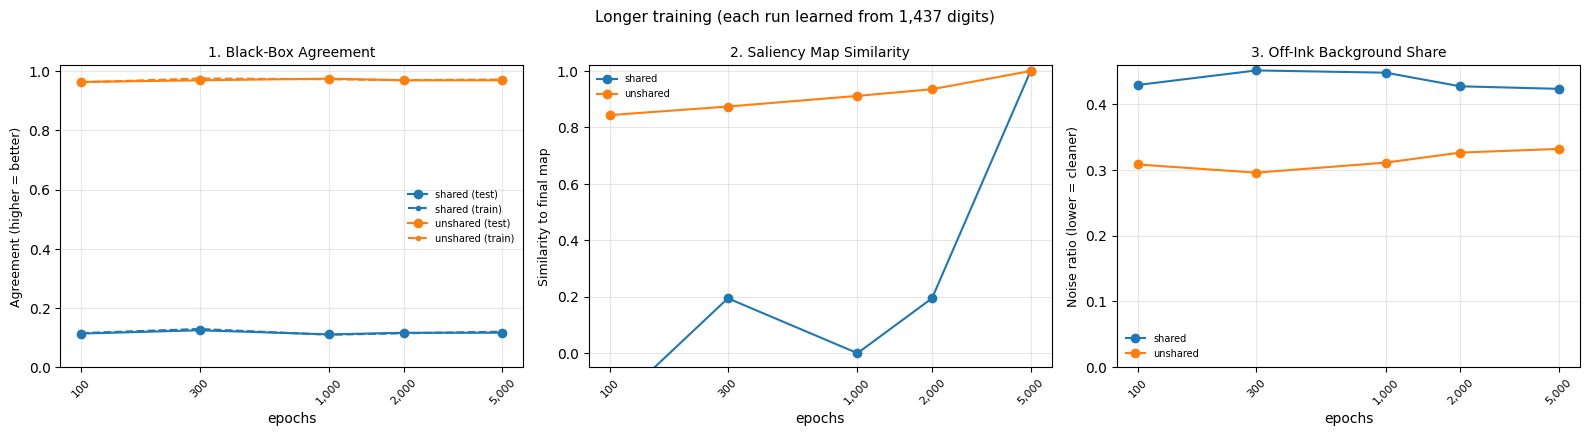

In [17]:
if EPOCH_SWEEP:
    charts(epoch_table, "epochs", "epochs", "chart_epochs.png",
           f"Longer training (each run learned from {EPOCH_SWEEP_SIZE:,} digits)")

### Saliency Map Evolution by Training Epochs (Rows: Test Digits, Columns: Training Epochs)

This grid visualizes how the signed saliency maps change as the optimization progresses for each class's representative test digit (0–9). The columns represent different training epoch markers (`EPOCH_SWEEP`) while keeping the dataset size fixed at `EPOCH_SWEEP_SIZE`.

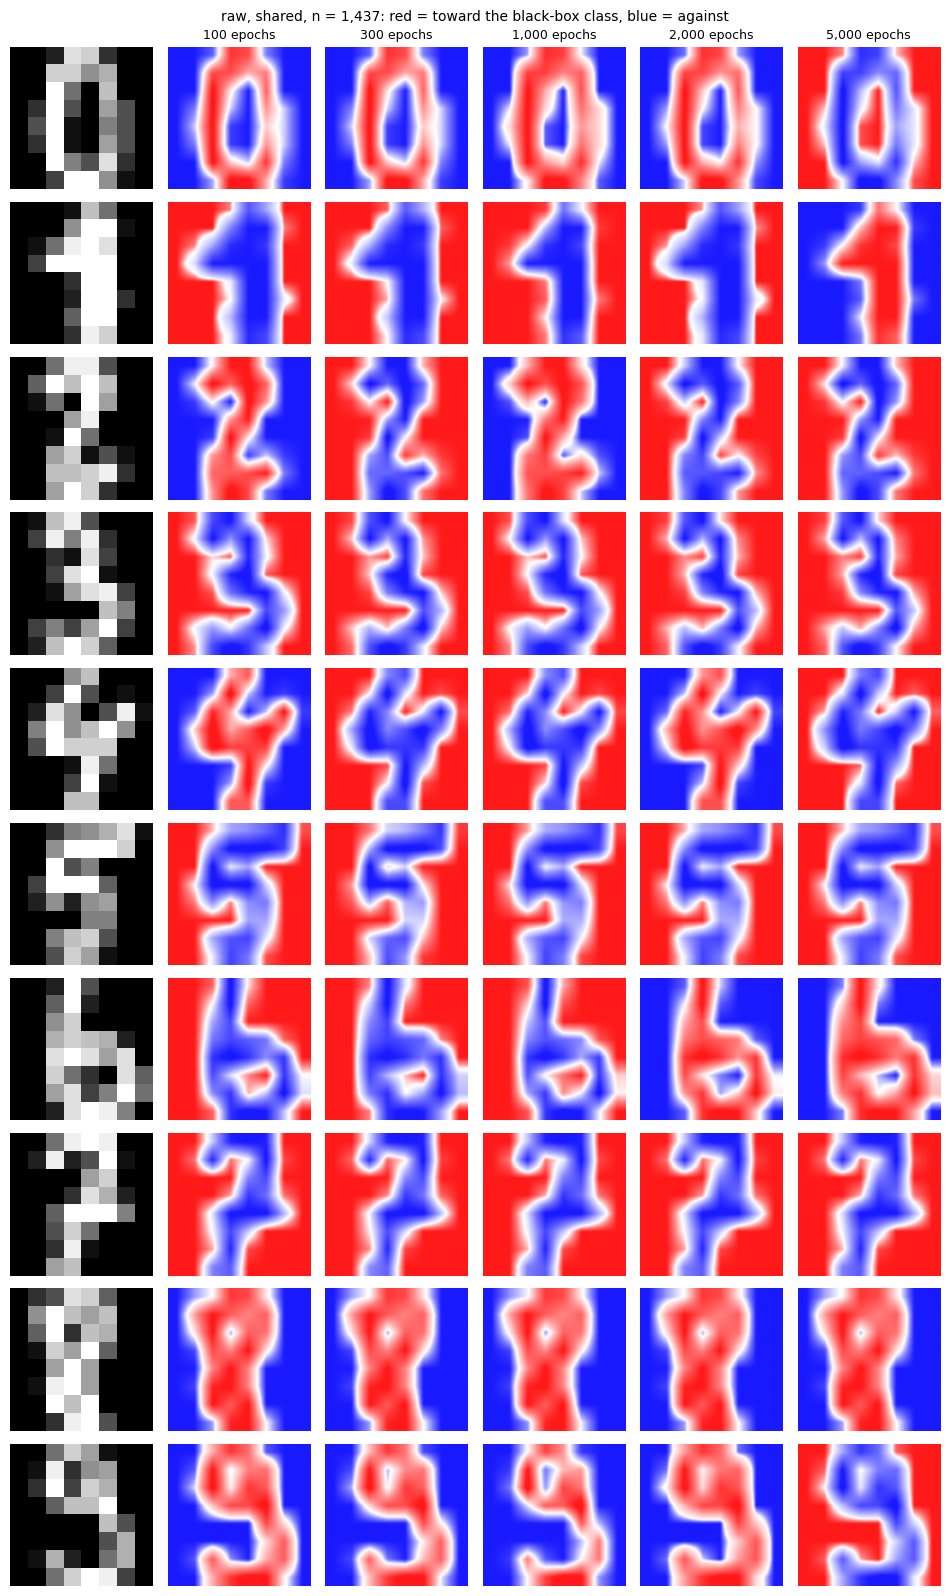

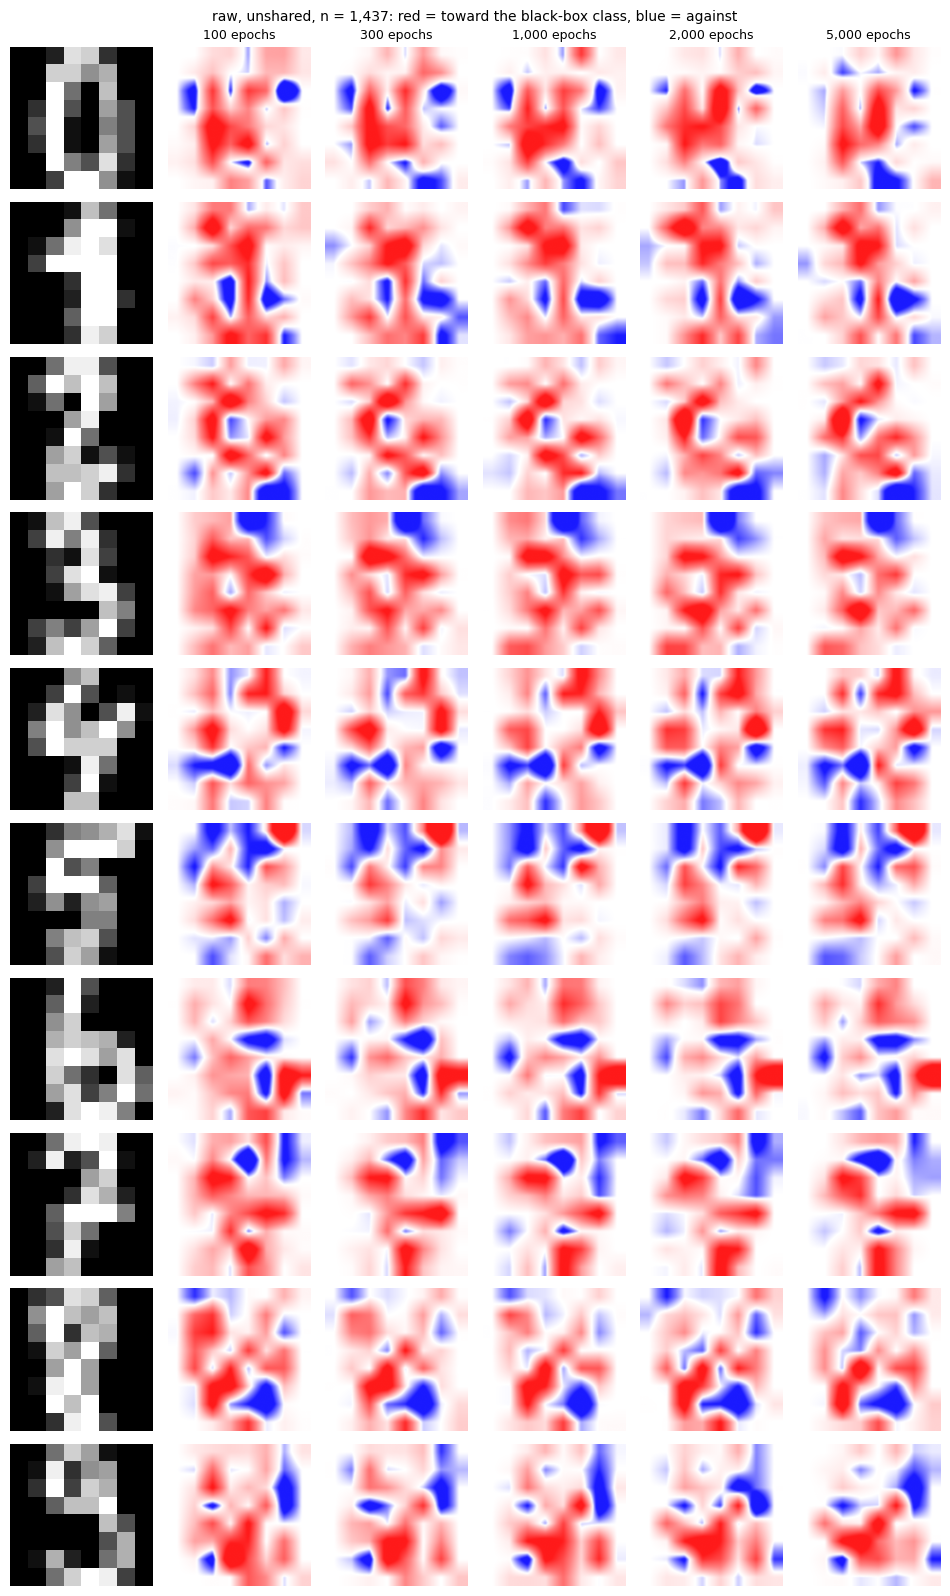

In [14]:
if EPOCH_SWEEP:
    for name in INPUTS:
        for mode in MODES:
            map_grid([fits[(name, mode, EPOCH_SWEEP_SIZE, e)]["map"] for e in EPOCH_SWEEP],
                     [f"{e:,} epochs" for e in EPOCH_SWEEP],
                     f"{name}, {mode}, n = {EPOCH_SWEEP_SIZE:,}", f"maps_epochs_{name}_{mode}.png")